# AgriStress-500 End-to-End Pipeline

Download the dataset -> sample a cluster -> generate embeddings via the PAI embedding API -> run Image-to-Image evaluation, using the `precisionai.agriemb` package that wires the three sibling projects together:

- [Precision AI Embeddings](https://embeddings.precision.ai/) - hosted image embedding API
- [`agrieval`](https://github.com/Precision-AI-Inc/agrieval) - embedding evaluation
- [`agristress-utils`](https://github.com/Precision-AI-Inc/agristress-utils) - dataset download and sampling

**Setup** (from the repo root, before starting Jupyter):

```bash
pip install -e ".[notebook]"
cp .env.example .env   # fill in PAI_EMBEDDINGS_BASE_URL and PAI_EMBEDDINGS_API_KEY
```

Run all cells top-to-bottom. See the root `README.md` and the standalone `examples/01_download_dataset.py` plus `examples/image2image/01_sample_cluster.py`-`03_run_eval.py` (or the bundled `04_end_to_end.py`) scripts for the non-notebook version.

In [ ]:
from IPython.display import display
from PIL import Image

from precisionai.agriemb import build_client, download, embed_images, run_i2i_evaluation, sample_cluster
from precisionai.agriemb.config import DEFAULT_DATASET_DIR, DEFAULT_MODEL, DEFAULT_REPO_ID
from precisionai.agrieval.emb import plot_cosine_similarity, plot_knn_confusion, plot_tsne, print_result
from precisionai.agristress.utils import AgriStressDataset, normalize_embeddings, validate_embeddings

SEED = 0
NUM_SAMPLES = 8

## 1. Download the dataset

In [ ]:
dataset_dir = download(DEFAULT_DATASET_DIR, repo_id=DEFAULT_REPO_ID)
dataset = AgriStressDataset(dataset_dir)
clusters = dataset.list_clusters()

print(f"Downloaded to {dataset_dir}")
print(f"Clusters : {len(clusters)}")
print(f"Images   : {len(dataset.list_image_ids())}")

## 2. Sample a cluster

Picks a random L2 cluster and draws `NUM_SAMPLES` images from it. Pass `cluster="A1"` (or any id from `clusters` above) to target a specific one.

In [3]:
cluster, sample = sample_cluster(dataset, cluster="A1", num_samples=NUM_SAMPLES, seed=SEED)
paths = dataset.resolve_paths(sample)

print(f"Cluster {cluster}: sampled {len(sample)} of {len(dataset.list_image_ids(cluster=cluster))} images")

Cluster A1: sampled 8 of 16 images


### Preview the sampled images

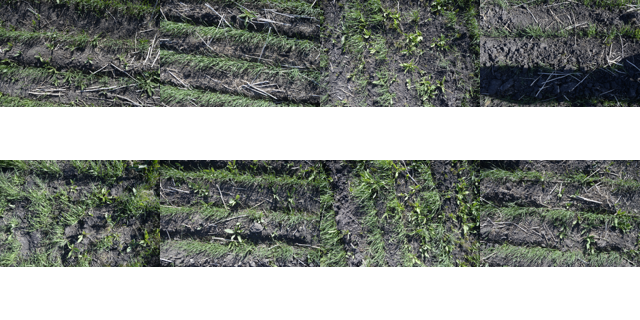

images/A1/pai-SbcQ1Av0.png
images/A1/pai-fMEceubf.png
images/A1/pai-Ooz3Qfkt.png
images/A1/pai-OtvXFt3d.png
images/A1/pai-WIjTCT7r.png
images/A1/pai-M2lh8fY1.png
images/A1/pai-UEr840F9.png
images/A1/pai-LsPNHYpV.png


In [4]:
thumb_size = 160
cols = 4
rows = (len(sample) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, image_id in enumerate(sample):
    thumb = Image.open(paths[image_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

display(sheet)
print("\n".join(sample))

## 3. Generate embeddings via the PAI embedding API

Each sampled image is base64-encoded as a `data:` URI and sent to the OpenAI-compatible PAI embedding API (https://embeddings.precision.ai/), then L2-normalized and validated.

In [5]:
client = build_client()
raw_embeddings = embed_images(client, paths, model=DEFAULT_MODEL)

embeddings = normalize_embeddings(raw_embeddings)
validate_embeddings(embeddings)

print(f"Generated {len(embeddings)} L2-normalized embeddings (dim={len(next(iter(embeddings.values())))})")

Generated 8 L2-normalized embeddings (dim=384)


## 4. Run Image-to-Image evaluation

`run_i2i_evaluation` assembles the explicit-positive metadata groups from `image2image.json` (via `AgriStressDataset.build_i2i_payload`) and evaluates them with `agrieval`'s `run_image2image_eval` for graded nDCG and per-attribute metrics.

In [6]:
result = run_i2i_evaluation(dataset, embeddings, k_values=[5, 10])
print_result(result)

n_items      : 8
embedding_dim: 384
classes      : ['A']
k_values     : [5, 7]

── global_metrics ──────────────────────────────────────────────────────
  pairwise cosine    : mean=0.9794  std=0.0121  (p05=0.9580  p50=0.9838  p95=0.9933)
  centroid cosine    : mean=0.9910  std=0.0064  norm=0.9910
  effective_rank     : 3.46  (ratio=0.0090  dim=384)
  uniformity         : -0.0811
  alignment          : 0.0411

  hubness@5         : mean=5.0000  std=2.6926  p95=7.0000
  hubness@7         : mean=7.0000  std=0.0000  p95=7.0000
  knn_radius@5         : mean=0.9797  std=0.0089  p05=0.9636  p95=0.9865
  knn_radius@7         : mean=0.9603  std=0.0066  p05=0.9509  p95=0.9687
  mean_top_k_sim@5         : mean=0.9844  std=0.0085  p05=0.9690  p95=0.9904
  mean_top_k_sim@7         : mean=0.9794  std=0.0073  p05=0.9666  p95=0.9852
  outlier_score@5         : mean=0.0156  std=0.0085  p95=0.0310
  outlier_score@7         : mean=0.0206  std=0.0073  p95=0.0334

  P@K (meta)@5         : mean=1.0000  std=

## 5. Visualize (optional)

Requires `precisionai-agrieval[analysis]` (already included in the `notebook` extra). `output_path=None` renders the interactive Plotly figure inline instead of saving an HTML file.

In [7]:
plot_cosine_similarity(embeddings, result, output_path=None)

In [8]:
plot_tsne(embeddings, result, output_path=None, dimensions=2)

  t-SNE 2D — fitting 8 samples (perplexity=3, iter=1000)...


In [9]:
plot_knn_confusion(result, k=5, output_path=None)